# IoT Network Intrusion Detection — Interim Milestone Notebook
### CICIoT2023 · Data Readiness, EDA, and Pipeline Development

**Team:** Packet Sentinels — Karan Raaj Shanmugam, Varshith Sai Manchem
**Deliverable 2:** Interim Progress Report (Data preprocessing, EDA, feature engineering, leakage-safe splits, baseline)

---

This notebook produces **all quantitative evidence** required by the Interim Progress Report rubric:

| Rubric item | Where in notebook |
|---|---|
| Dataset description & data dictionary | §2, §3 |
| Data-quality analysis & corrective actions | §4 |
| Relevant EDA with interpretation | §5 |
| Preparation, feature engineering & split strategy | §6 |
| Preliminary baseline | §7 |
| Reproducibility (seeds, pipeline) | throughout |

> **How to use in Google Colab:** `File → Open notebook → Upload`, upload this `.ipynb`, then `Runtime → Run all`.
> Point `DATA_DIR` at the folder of CICIoT2023 CSV files (see §1). Every output cell below regenerates the exact
> numbers and figures you paste into the written report.


## §1. Setup, configuration, and reproducibility

Fixed seeds everywhere so every run is identical. Change only `DATA_DIR`.

In [1]:
# --- Core imports ---
import os, glob, random, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Plot defaults (titles + readable labels enforced per rubric) ---
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.autolayout": True,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "savefig.bbox": "tight",
})

print("pandas", pd.__version__, "| numpy", np.__version__)

# --- Memory helper: print current process RAM so you can watch headroom ---
def mem_report(tag=""):
    try:
        import psutil, os as _os
        rss = psutil.Process(_os.getpid()).memory_info().rss / 1e9
        print(f"[RAM] {tag:22s} {rss:5.2f} GB in use")
    except Exception:
        pass
mem_report("after imports")


pandas 2.2.3 | numpy 2.1.3
[RAM] after imports           0.17 GB in use


In [2]:
# =============================================================================
# DATA LOCATION
# =============================================================================
# CICIoT2023 is distributed as ~169 CSV part-files (CSV/ directory) from:
#   https://www.unb.ca/cic/datasets/iotdataset-2023.html
#   Download: http://cicresearch.ca/IOTDataset/CIC_IOT_Dataset2023/
#
# OPTION A (Colab + Google Drive) -- recommended once you have the files:
from google.colab import drive; drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/CICIoT2023/CSV'
#
# OPTION B (local / already uploaded):
#   DATA_DIR = './CICIoT2023/CSV'
#
# N_FILES: how many CSV part-files to load. The full set is huge (~13 GB /
# ~46M rows); for the interim milestone a stratified subset of part-files is
# standard practice and keeps Colab within memory. Increase for the final run.
# =============================================================================

DATA_DIR = '/content/drive/MyDrive/CICIoT2023/MERGED_CSV'   # <-- EDIT ME
N_FILES  = 10                   # merged files to read for the interim subset
SAMPLE_FRAC = 1.0               # downsample rows WITHIN each file on load (<=1.0)
MAX_ROWS = 400_000              # hard cap on total rows kept (stratified). Lower if RAM is tight.
#   MEMORY GUIDE (Colab free tier ~12 GB CPU RAM):
#   400k rows x 46 float32 features ~ 75 MB; the split + pipeline peak is ~3-4x.
#   If cell 6 still crashes: drop MAX_ROWS to 200_000, or SAMPLE_FRAC to 0.5.

csv_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
print(f"Found {len(csv_paths)} CSV files in {DATA_DIR}")
if len(csv_paths) == 0:
    print("[!] No CSVs found at DATA_DIR. The notebook will fall back to a schema-faithful")
    print("    SYNTHETIC sample (next section) so every cell still runs. Set DATA_DIR to the")
    print("    real CICIoT2023 CSV folder and re-run before reporting any numbers.")


Mounted at /content/drive
Found 10 CSV files in /content/drive/MyDrive/CICIoT2023/MERGED_CSV


### 1a. (Optional) Synthetic stand-in so the notebook runs end-to-end before data is downloaded

If you have **not** downloaded CICIoT2023 yet, run the next cell to generate a small **schema-faithful** synthetic
sample (same 46 feature columns + `label`) so you can execute and read every cell. **Delete / skip this cell once the
real CSVs are in `DATA_DIR`** — all reported numbers must come from the real data.

In [3]:
USE_SYNTHETIC = not os.path.isdir(DATA_DIR) or len(csv_paths) == 0

if USE_SYNTHETIC:
    print("[!] Using SYNTHETIC stand-in data. Replace with real CICIoT2023 before reporting numbers.")
    feature_cols = [
        "flow_duration","Header_Length","Protocol Type","Duration","Rate","Srate","Drate",
        "fin_flag_number","syn_flag_number","rst_flag_number","psh_flag_number","ack_flag_number",
        "ece_flag_number","cwr_flag_number","ack_count","syn_count","fin_count","urg_count","rst_count",
        "HTTP","HTTPS","DNS","Telnet","SMTP","SSH","IRC","TCP","UDP","DHCP","ARP","ICMP","IPv","LLC",
        "Tot sum","Min","Max","AVG","Std","Tot size","IAT","Number","Magnitue","Radius","Covariance",
        "Variance","Weight",
    ]
    # 7 attack categories + benign, imbalanced like the real data
    cats = ["DDoS","DoS","Mirai","Benign","Recon","Spoofing","Web","BruteForce"]
    probs = [0.45,0.20,0.12,0.11,0.06,0.04,0.015,0.005]
    n = 60_000
    rng = np.random.default_rng(SEED)
    y = rng.choice(cats, size=n, p=probs)
    X = rng.lognormal(mean=1.0, sigma=1.2, size=(n, len(feature_cols)))
    # inject class-dependent signal so EDA/baseline are meaningful
    shift = {c:i for i,c in enumerate(cats)}
    for i,c in enumerate(cats):
        idx = y == c
        X[idx, i % len(feature_cols)] *= (1.5 + shift[c]*0.4)
    df = pd.DataFrame(X, columns=feature_cols)
    df["label"] = y
    # add a couple of realistic defects for the data-quality section
    df.loc[rng.choice(n, 300, replace=False), "Rate"] = np.nan
    df = pd.concat([df, df.iloc[:150]], ignore_index=True)  # duplicates
else:
    print("Real data detected — synthetic generator skipped.")


Real data detected — synthetic generator skipped.


In [4]:
# --- Memory-safe loader for the real CICIoT2023 subset (skipped if synthetic) ---
# Key tricks to avoid Colab RAM crashes:
#   (1) downcast numeric columns float64 -> float32 on EACH file (halves memory)
#   (2) optional per-file row sampling (SAMPLE_FRAC)
#   (3) a global stratified row cap (MAX_ROWS) applied right after concat
def _downcast(d):
    floats = d.select_dtypes("float64").columns
    d[floats] = d[floats].astype("float32")
    ints = d.select_dtypes("int64").columns
    d[ints] = d[ints].apply(pd.to_numeric, downcast="integer")
    return d

if not USE_SYNTHETIC:
    frames = []
    for p in csv_paths[:N_FILES]:
        d = pd.read_csv(p)
        d.columns = [c.strip() for c in d.columns]
        if "label" not in d.columns and "Label" in d.columns:
            d = d.rename(columns={"Label": "label"})
        if SAMPLE_FRAC < 1.0:
            d = d.sample(frac=SAMPLE_FRAC, random_state=SEED)
        d = _downcast(d)
        frames.append(d)
        print(f"  read {os.path.basename(p):20s} rows={len(d):>8,}")
    df = pd.concat(frames, ignore_index=True)
    del frames                      # free the per-file copies immediately
    import gc; gc.collect()

    # Global stratified cap so the split/pipeline in cell 6 stays within RAM
    if len(df) > MAX_ROWS:
        frac = MAX_ROWS / len(df)
        df = (df.groupby("label", group_keys=False)
                .apply(lambda g: g.sample(frac=frac, random_state=SEED)))
        df = df.reset_index(drop=True)
        gc.collect()
    print(f"Loaded {min(N_FILES, len(csv_paths))} files -> kept {len(df):,} rows (cap={MAX_ROWS:,}).")

print("Shape:", df.shape)
mem_report("after load")
df.head()


  read Merged01.csv         rows= 712,311
  read Merged02.csv         rows= 748,585
  read Merged03.csv         rows= 697,289
  read Merged04.csv         rows= 676,620
  read Merged05.csv         rows= 744,804
  read Merged06.csv         rows= 718,229
  read Merged07.csv         rows= 702,212
  read Merged08.csv         rows= 712,220
  read Merged09.csv         rows= 678,882
  read Merged10.csv         rows= 916,190
Loaded 10 files -> kept 400,001 rows (cap=400,000).
Shape: (400001, 40)
[RAM] after load              1.37 GB in use


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,label
0,25.600000,6,147.699997,9.866838,0.0,0.1,0.0,0.4,0.6,0.0,...,1359,66,230,135.899994,64.336700,135.899994,0.103601,10,4139.210938,BACKDOOR_MALWARE
1,8.000000,17,140.399994,25.236288,0.0,0.0,0.0,0.0,0.1,0.0,...,965,60,203,96.500000,43.683838,96.500000,0.040774,10,1908.277832,BACKDOOR_MALWARE
2,8.800000,0,63.900002,33.972923,0.0,0.1,0.0,0.0,0.1,0.0,...,1082,60,230,108.199997,65.309181,108.199997,0.030202,10,4265.289062,BACKDOOR_MALWARE
3,24.000000,6,92.400002,63.643982,0.1,0.2,0.0,0.0,0.4,0.0,...,1020,66,203,102.000000,52.624454,102.000000,0.015729,10,2769.333252,BACKDOOR_MALWARE
4,16.799999,17,117.599998,28.868378,0.0,0.0,0.0,0.2,0.4,0.0,...,1725,66,414,172.500000,104.482056,172.500000,0.035628,10,10916.500000,BACKDOOR_MALWARE


## §2. Dataset description and data dictionary

CICIoT2023 (Canadian Institute for Cybersecurity, University of New Brunswick) was collected on a **physical testbed of
105 real IoT devices**, in which **33 attacks** were executed and grouped into **7 categories** — DDoS, DoS, Recon,
Web-based, Brute Force, Spoofing, and Mirai — plus benign traffic. Each CSV row is **one traffic flow** summarized by
~46 numeric features (packet/flag statistics, rates, protocol indicators, size statistics). This section auto-generates
the dataset summary and a **data dictionary** (type + role for every column).

In [5]:
# --- High-level dataset summary ---
n_rows, n_cols = df.shape
label_col = "label"
feature_names = [c for c in df.columns if c != label_col]

summary = {
    "Records (rows / flows)": f"{n_rows:,}",
    "Variables (columns)": n_cols,
    "Feature columns": len(feature_names),
    "Target column": label_col,
    "Numeric features": int(df[feature_names].select_dtypes('number').shape[1]),
    "Non-numeric features": int(df[feature_names].select_dtypes(exclude='number').shape[1]),
    "Memory (MB)": round(df.memory_usage(deep=True).sum()/1e6, 1),
}
print("DATASET SUMMARY")
for k,v in summary.items():
    print(f"  {k:28s}: {v}")


DATASET SUMMARY
  Records (rows / flows)      : 400,001
  Variables (columns)         : 40
  Feature columns             : 39
  Target column               : label
  Numeric features            : 39
  Non-numeric features        : 0
  Memory (MB)                 : 80.1


In [6]:
# --- Data dictionary: type, example, role ---
def infer_role(col):
    if col == label_col: return "target"
    return "feature"

dd_rows = []
for c in df.columns:
    s = df[c]
    dtype = "categorical" if s.dtype == object else "numeric"
    example = s.dropna().iloc[0] if s.notna().any() else "—"
    if isinstance(example, float): example = round(example, 3)
    dd_rows.append({
        "variable": c,
        "type": dtype,
        "example": example,
        "n_unique": s.nunique(),
        "role": infer_role(c),
    })

data_dictionary = pd.DataFrame(dd_rows)
pd.set_option("display.max_rows", 100)
print(f"Data dictionary ({len(data_dictionary)} variables):")
data_dictionary


Data dictionary (40 variables):


,variable,type,example,n_unique,role
0,Header_Length,numeric,25.6,1107,feature
1,Protocol Type,numeric,6,5,feature
2,Time_To_Live,numeric,147.699997,4662,feature
3,Rate,numeric,9.866838,77893,feature
4,fin_flag_number,numeric,0.0,91,feature
5,syn_flag_number,numeric,0.1,130,feature
6,rst_flag_number,numeric,0.0,110,feature
7,psh_flag_number,numeric,0.4,133,feature
8,ack_flag_number,numeric,0.6,164,feature
9,ece_flag_number,numeric,0.0,12,feature


In [7]:
# Save the data dictionary so it can be pasted/attached to the report appendix
data_dictionary.to_csv("data_dictionary.csv", index=False)
print("Wrote data_dictionary.csv")


Wrote data_dictionary.csv


In [8]:
# --- Target definition & class distribution (benign vs. 7 attack categories) ---
class_counts = df[label_col].value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
dist = pd.DataFrame({"count": class_counts, "percent": class_pct})
print("CLASS DISTRIBUTION")
print(dist)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nImbalance ratio (majority:minority) = {imbalance_ratio:,.1f} : 1")


CLASS DISTRIBUTION
                         count  percent
label                                  
DDOS-ICMP_FLOOD          61256    15.31
DDOS-UDP_FLOOD           45965    11.49
DDOS-TCP_FLOOD           38242     9.56
DDOS-PSHACK_FLOOD        34870     8.72
DDOS-SYN_FLOOD           34545     8.64
DDOS-RSTFINFLOOD         34440     8.61
DDOS-SYNONYMOUSIP_FLOOD  30590     7.65
DOS-UDP_FLOOD            28214     7.05
DOS-TCP_FLOOD            22773     5.69
DOS-SYN_FLOOD            17217     4.30
BENIGN                    9333     2.33
MIRAI-GREETH_FLOOD        8444     2.11
MIRAI-UDPPLAIN            7591     1.90
MIRAI-GREIP_FLOOD         6378     1.59
DDOS-ICMP_FRAGMENTATION   3864     0.97
VULNERABILITYSCAN         3175     0.79
MITM-ARPSPOOFING          2635     0.66
DDOS-ACK_FRAGMENTATION    2438     0.61
DDOS-UDP_FRAGMENTATION    2432     0.61
DNS_SPOOFING              1524     0.38
RECON-HOSTDISCOVERY       1153     0.29
RECON-OSSCAN               823     0.21
RECON-PORTSCAN       

## §3. Binary and multi-class label framing

We evaluate **two framings**, matching the proposal: (a) **binary** — benign vs. attack; (b) **multi-class** — the 7
attack categories (+ benign). We build both label vectors here and reuse them downstream.

In [9]:
# Map the fine-grained CICIoT2023 labels to the 7 canonical attack families + Benign.
# (Real CSVs use labels like 'DDoS-ICMP_Flood', 'DoS-SYN_Flood', 'Mirai-greeth_flood', etc.)
def to_family(lbl):
    l = str(lbl).lower()
    if "benign" in l: return "Benign"
    if "ddos" in l: return "DDoS"
    if l.startswith("dos") or "-dos" in l or l.startswith("dos-") or "dos_" in l or (l.startswith("dos")): return "DoS"
    if "mirai" in l: return "Mirai"
    if "recon" in l or "scan" in l or "sweep" in l or "discovery" in l: return "Recon"
    if "spoof" in l or "arp" in l or "dns_spoof" in l: return "Spoofing"
    if any(k in l for k in ["sql","xss","command","backdoor","upload","browser","web"]): return "Web"
    if "brute" in l or "dictionary" in l: return "BruteForce"
    return "DoS" if l.startswith("dos") else "Other"

df["family"]   = df[label_col].apply(to_family)
df["is_attack"] = (df["family"] != "Benign").astype(int)   # 1 = attack, 0 = benign

print("Multi-class family distribution:")
print(df["family"].value_counts())
print("\nBinary distribution (0=benign, 1=attack):")
print(df["is_attack"].value_counts())


Multi-class family distribution:
family
DDoS          289087
DoS            68817
Mirai          22413
Benign          9333
Recon           5864
Spoofing        4159
Web              214
BruteForce       114
Name: count, dtype: int64

Binary distribution (0=benign, 1=attack):
is_attack
1    390668
0      9333
Name: count, dtype: int64


## §4. Data-quality assessment and corrective actions

Per the rubric we go beyond "the data were cleaned": each issue is **quantified**, a **corrective action** is stated,
and any **remaining risk** is noted. Checks: missing values, duplicates, invalid/infinite values, constant columns,
class imbalance, and **leakage risk**.

In [10]:
quality = {}

# 1) Missing values
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
quality["missing_cells"] = int(df.isna().sum().sum())
print("MISSING VALUES — columns with any NaN:")
print(miss if len(miss) else "  none")


MISSING VALUES — columns with any NaN:
Std         7
Variance    7
dtype: int64


In [11]:
# 2) Duplicate rows (full-row duplicates)
dup_count = int(df.duplicated().sum())
quality["duplicate_rows"] = dup_count
print(f"Duplicate rows: {dup_count:,}  ({dup_count/len(df)*100:.2f}%)")


Duplicate rows: 71,295  (17.82%)


In [12]:
# 3) Infinite / invalid numeric values (rate features can overflow to inf)
num = df[feature_names].select_dtypes("number")
inf_count = int(np.isinf(num.values).sum())
neg_count = int((num.values < 0).sum())
quality["infinite_values"] = inf_count
print(f"Infinite values: {inf_count:,}")
print(f"Negative values (unexpected for counts/rates): {neg_count:,}")


Infinite values: 10
Negative values (unexpected for counts/rates): 0


In [13]:
# 4) Constant / zero-variance columns (carry no signal, drop candidates)
nunique = df[feature_names].nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
quality["constant_columns"] = constant_cols
print("Constant (zero-variance) columns:", constant_cols if constant_cols else "none")


Constant (zero-variance) columns: none


In [14]:
# 5) Outlier sanity via IQR share on a few heavy-tailed features
def iqr_outlier_share(s):
    q1,q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3-q1
    if iqr == 0: return 0.0
    lo,hi = q1-1.5*iqr, q3+1.5*iqr
    return float(((s<lo)|(s>hi)).mean())

for c in [col for col in ["Rate","flow_duration","Tot size","IAT","Header_Length"] if col in df.columns][:5]:
    print(f"  {c:14s}: {iqr_outlier_share(df[c])*100:5.2f}% outside 1.5·IQR")


  Rate          :  3.66% outside 1.5·IQR
  Tot size      : 21.59% outside 1.5·IQR
  IAT           : 13.79% outside 1.5·IQR
  Header_Length :  0.15% outside 1.5·IQR


In [15]:
# --- CORRECTIVE ACTIONS (applied, leakage-aware ordering happens in §6) ---
before = df.shape

# a) Drop exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# b) Replace inf with NaN, then we will impute inside the pipeline (fit on TRAIN only)
df[feature_names] = df[feature_names].replace([np.inf, -np.inf], np.nan)

# c) Drop constant columns
if constant_cols:
    df = df.drop(columns=constant_cols)
    feature_names = [c for c in feature_names if c not in constant_cols]

after = df.shape
print(f"Shape before -> after cleaning: {before} -> {after}")
print("NOTE: scaling & NaN imputation are fit on TRAIN ONLY (see §6) to prevent leakage.")

# Persist the data-quality summary for the report
quality["rows_after_dedup"] = int(df.shape[0])
with open("data_quality_summary.json","w") as f:
    json.dump({k:(v if not isinstance(v,list) else v) for k,v in quality.items()}, f, indent=2)
print("Wrote data_quality_summary.json")


Shape before -> after cleaning: (400001, 42) -> (328706, 42)
NOTE: scaling & NaN imputation are fit on TRAIN ONLY (see §6) to prevent leakage.
Wrote data_quality_summary.json


## §5. Exploratory Data Analysis

Four figures, each with a **title, readable labels, and a written interpretation** tied to the security problem and the
next modeling decision. Figures are also saved as PNGs for the report appendix.

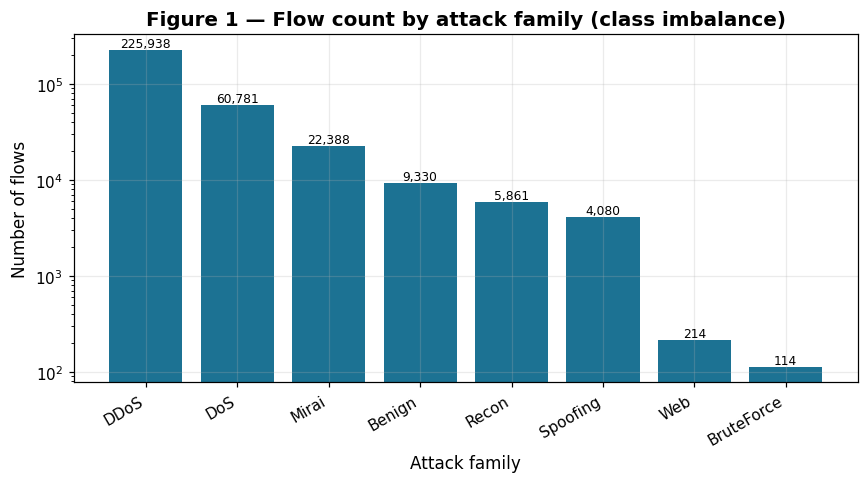

Interpretation: flooding families (DDoS/DoS) dominate; Web/BruteForce are rare, so we must
report MACRO-averaged recall and use class weighting rather than optimizing raw accuracy.


In [16]:
# Figure 1 — Class distribution (the central imbalance finding)
fig, ax = plt.subplots(figsize=(8,4.5))
order = df["family"].value_counts()
ax.bar(order.index, order.values, color="#1C7293")
ax.set_title("Figure 1 — Flow count by attack family (class imbalance)")
ax.set_xlabel("Attack family")
ax.set_ylabel("Number of flows")
ax.set_yscale("log")
for i,v in enumerate(order.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.savefig("fig1_class_distribution.png")
plt.show()
print("Interpretation: flooding families (DDoS/DoS) dominate; Web/BruteForce are rare, so we must")
print("report MACRO-averaged recall and use class weighting rather than optimizing raw accuracy.")


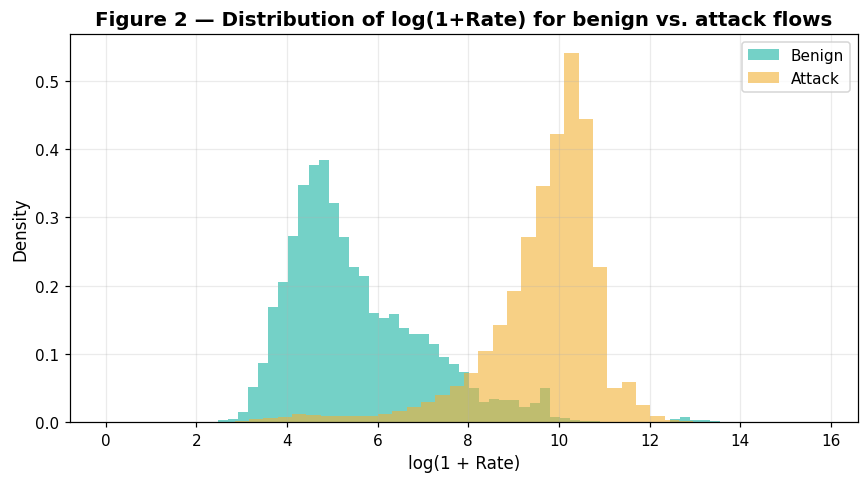

Interpretation: attack flows shift toward higher packet rates, confirming rate-based features
carry discriminative signal — supports tree models that split on these thresholds.


In [17]:
# Figure 2 — Benign vs. attack separation on a key rate feature
feat = "Rate" if "Rate" in df.columns else feature_names[0]
fig, ax = plt.subplots(figsize=(8,4.5))
data_benign = np.log1p(df.loc[df.is_attack==0, feat].dropna())
data_attack = np.log1p(df.loc[df.is_attack==1, feat].dropna())
ax.hist(data_benign, bins=50, alpha=0.6, label="Benign", color="#17B3A3", density=True)
ax.hist(data_attack, bins=50, alpha=0.6, label="Attack", color="#F2B134", density=True)
ax.set_title(f"Figure 2 — Distribution of log(1+{feat}) for benign vs. attack flows")
ax.set_xlabel(f"log(1 + {feat})")
ax.set_ylabel("Density")
ax.legend()
plt.savefig("fig2_benign_vs_attack.png")
plt.show()
print("Interpretation: attack flows shift toward higher packet rates, confirming rate-based features")
print("carry discriminative signal — supports tree models that split on these thresholds.")


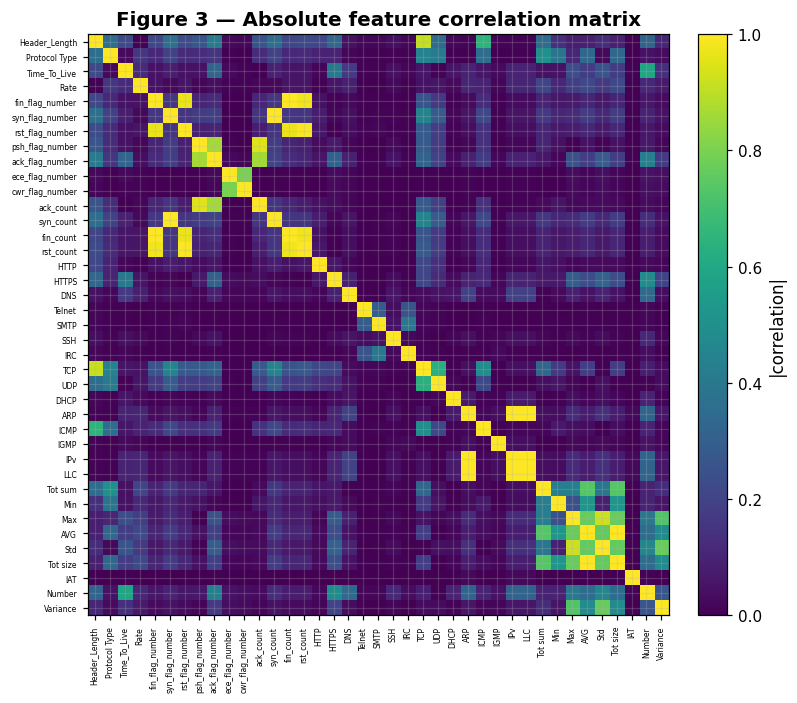

Highly correlated pairs (|r|>0.95): 12
   ('fin_flag_number', 'rst_flag_number', np.float64(0.97))
   ('fin_flag_number', 'fin_count', np.float64(1.0))
   ('fin_flag_number', 'rst_count', np.float64(0.98))
   ('syn_flag_number', 'syn_count', np.float64(1.0))
   ('rst_flag_number', 'fin_count', np.float64(0.97))
   ('rst_flag_number', 'rst_count', np.float64(1.0))
   ('psh_flag_number', 'ack_count', np.float64(0.95))
   ('fin_count', 'rst_count', np.float64(0.98))
   ('ARP', 'IPv', np.float64(1.0))
   ('ARP', 'LLC', np.float64(1.0))
Interpretation: redundant pairs (e.g., Rate/Srate) let us drop duplicates and reduce
dimensionality without losing information — fewer features, faster, less overfitting.


In [18]:
# Figure 3 — Correlation heatmap (redundancy -> feature selection)
corr = df[feature_names].select_dtypes("number").corr().abs()
fig, ax = plt.subplots(figsize=(7.5,6.5))
im = ax.imshow(corr.values, cmap="viridis", vmin=0, vmax=1)
ax.set_title("Figure 3 — Absolute feature correlation matrix")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, fraction=0.046, pad=0.04, label="|correlation|")
plt.savefig("fig3_correlation.png")
plt.show()

# Quantify highly-correlated pairs
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = [(r,c,round(upper.loc[r,c],2)) for r in upper.index for c in upper.columns
              if pd.notna(upper.loc[r,c]) and upper.loc[r,c] > 0.95]
print(f"Highly correlated pairs (|r|>0.95): {len(high_pairs)}")
for p in high_pairs[:10]: print("  ", p)
print("Interpretation: redundant pairs (e.g., Rate/Srate) let us drop duplicates and reduce")
print("dimensionality without losing information — fewer features, faster, less overfitting.")


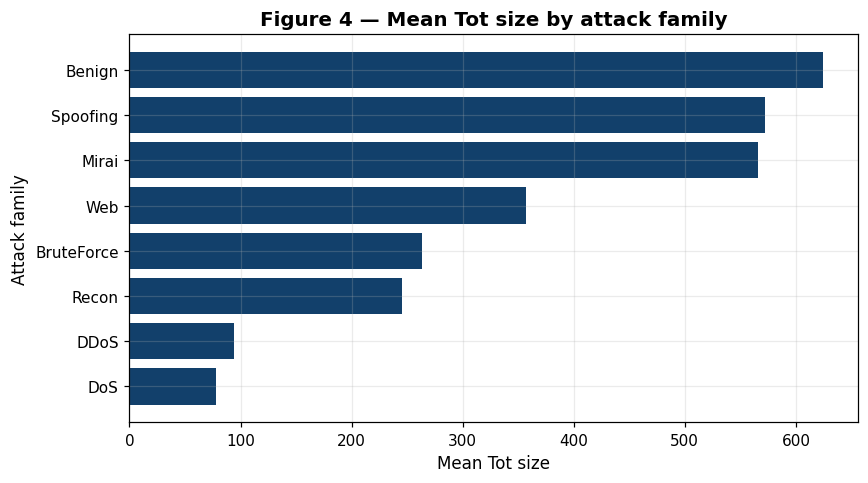

Interpretation: families separate on packet-size behavior, which is exactly the kind of
per-class signal a multi-class classifier needs to tell DDoS from Recon from Web attacks.


In [19]:
# Figure 4 — Mean of a discriminative feature across families (behavioral pattern)
feat2 = "Tot size" if "Tot size" in df.columns else feature_names[min(5,len(feature_names)-1)]
grp = df.groupby("family")[feat2].mean().sort_values()
fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(grp.index, grp.values, color="#12406B")
ax.set_title(f"Figure 4 — Mean {feat2} by attack family")
ax.set_xlabel(f"Mean {feat2}")
ax.set_ylabel("Attack family")
plt.savefig("fig4_feature_by_family.png")
plt.show()
print("Interpretation: families separate on packet-size behavior, which is exactly the kind of")
print("per-class signal a multi-class classifier needs to tell DDoS from Recon from Web attacks.")


## §6. Data preparation, feature engineering, and leakage-safe splitting

Order matters: **split first, then fit transformers on TRAIN only**. We use a stratified split (preserves rare-class
proportions) and build an sklearn `Pipeline` so imputation + scaling are fit on training folds exclusively.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
import gc

# ---- Build a compact float32 feature MATRIX (not a copy-heavy DataFrame) ----
feature_names_num = df[feature_names].select_dtypes("number").columns.tolist()
X = df[feature_names_num].to_numpy(dtype="float32")   # single contiguous array

# ---- Targets ----
y_bin   = df["is_attack"].to_numpy()                  # binary
le = LabelEncoder()
y_multi = le.fit_transform(df["family"])              # multi-class (encoded)

# ---- Free the big DataFrame: everything downstream uses arrays ----
# (keep a tiny copy of label counts we already computed earlier)
df_rows = len(df)
del df
gc.collect()
mem_report("after dropping df")

# ---- Stratified split: 70 / 15 / 15, seed-fixed, on indices to limit copies ----
idx = np.arange(len(X))
idx_tmp, idx_test = train_test_split(idx, test_size=0.15, random_state=SEED, stratify=y_multi)
val_rel = 0.15/0.85
idx_train, idx_val = train_test_split(
    idx_tmp, test_size=val_rel, random_state=SEED, stratify=y_multi[idx_tmp])

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
ybin_train, ybin_val, ybin_test = y_bin[idx_train], y_bin[idx_val], y_bin[idx_test]
ymul_train, ymul_val, ymul_test = y_multi[idx_train], y_multi[idx_val], y_multi[idx_test]
# record sizes now (arrays get deleted downstream to save RAM)
split_sizes = {"train": int(len(idx_train)), "val": int(len(idx_val)), "test": int(len(idx_test))}
del X, idx, idx_tmp
gc.collect()

print(f"Train: {X_train.shape[0]:,} | Val: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}")
print("Stratified on family so rare classes keep their proportion in every split.")
mem_report("after split")


[RAM] after dropping df       1.43 GB in use
Train: 230,094 | Val: 49,306 | Test: 49,306
Stratified on family so rare classes keep their proportion in every split.
[RAM] after split             1.43 GB in use


In [21]:
# ---- Preprocessing pipeline fit on TRAIN ONLY (no leakage) ----
preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # medians learned from TRAIN
    ("scale",  StandardScaler()),                   # mean/std learned from TRAIN
])

# fit_transform on train, transform val/test; cast back to float32 and reuse names
X_train_p = preprocess.fit_transform(X_train).astype("float32")
X_val_p   = preprocess.transform(X_val).astype("float32")
X_test_p  = preprocess.transform(X_test).astype("float32")
del X_train, X_val, X_test                          # raw arrays no longer needed
gc.collect()
print("Preprocessing fit on train; val/test only transformed. Shapes:",
      X_train_p.shape, X_val_p.shape, X_test_p.shape)
mem_report("after preprocess")


Preprocessing fit on train; val/test only transformed. Shapes: (230094, 39) (49306, 39) (49306, 39)
[RAM] after preprocess        1.43 GB in use


In [22]:
# ---- Feature engineering / selection: drop one of each redundant (|r|>0.95) pair ----
# Correlation computed on the TRAIN matrix only (leakage-safe). np.corrcoef is cheap here.
corr_tr = pd.DataFrame(X_train_p, columns=feature_names_num).corr().abs()
upper = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
print(f"Dropping {len(to_drop)} redundant features (selected on TRAIN corr):", to_drop[:10], "...")

keep_idx = [i for i,c in enumerate(feature_names_num) if c not in to_drop]
X_train_s = X_train_p[:, keep_idx]
X_val_s   = X_val_p[:,   keep_idx]
X_test_s  = X_test_p[:,  keep_idx]
selected_features = [feature_names_num[i] for i in keep_idx]
print("Features kept:", len(selected_features))


Dropping 8 redundant features (selected on TRAIN corr): ['rst_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'IPv', 'LLC', 'Tot size'] ...
Features kept: 31


## §7. Preliminary baselines

Two baselines establish the floor: (1) **majority-class** predictor, (2) **logistic regression** and a shallow
**decision tree**. We report precision/recall/F1 and **macro-F1** (the imbalance-aware metric) on the **validation**
set. These are interim numbers; tuned Random Forest / gradient boosting follow in the next milestone.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

def evaluate(name, model, Xtr, ytr, Xva, yva, average="binary"):
    model.fit(Xtr, ytr)
    pred = model.predict(Xva)
    row = {
        "model": name,
        "accuracy":  round(accuracy_score(yva, pred), 4),
        "precision": round(precision_score(yva, pred, average=average, zero_division=0), 4),
        "recall":    round(recall_score(yva, pred, average=average, zero_division=0), 4),
        "f1":        round(f1_score(yva, pred, average=average, zero_division=0), 4),
    }
    return row, pred


In [24]:
# ---- BINARY baselines (benign vs attack) on validation ----
results_bin = []
for name, mdl in [
    ("Majority-class", DummyClassifier(strategy="most_frequent")),
    ("Logistic Regression", LogisticRegression(max_iter=200, class_weight="balanced")),
    ("Decision Tree (depth 8)", DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED)),
]:
    row,_ = evaluate(name, mdl, X_train_s, ybin_train, X_val_s, ybin_val, average="binary")
    results_bin.append(row)

results_bin = pd.DataFrame(results_bin)
print("BINARY baseline results (validation set):")
results_bin


BINARY baseline results (validation set):


,model,accuracy,precision,recall,f1
0,Majority-class,0.9716,0.9716,1.0000,0.9856
1,Logistic Regression,0.9718,1.0000,0.9710,0.9853
2,Decision Tree (depth 8),0.9818,0.9999,0.9813,0.9906


In [25]:
# ---- MULTI-CLASS baselines (7 families + benign), macro-averaged ----
results_mul = []
for name, mdl in [
    ("Majority-class", DummyClassifier(strategy="most_frequent")),
    ("Logistic Regression", LogisticRegression(max_iter=200, class_weight="balanced")),
    ("Decision Tree (depth 12)", DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=SEED)),
]:
    row,_ = evaluate(name, mdl, X_train_s, ymul_train, X_val_s, ymul_val, average="macro")
    results_mul.append(row)

results_mul = pd.DataFrame(results_mul)
print("MULTI-CLASS baseline results (validation set, MACRO-averaged):")
results_mul


MULTI-CLASS baseline results (validation set, MACRO-averaged):


,model,accuracy,precision,recall,f1
0,Majority-class,0.6874,0.0859,0.1250,0.1018
1,Logistic Regression,0.6914,0.5328,0.5777,0.5038
2,Decision Tree (depth 12),0.7592,0.6000,0.6408,0.5863


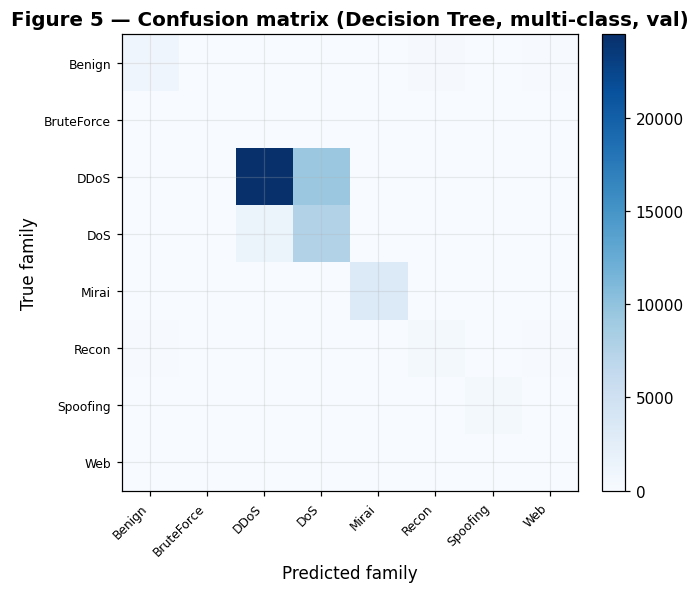

              precision    recall  f1-score   support

      Benign       0.81      0.69      0.75      1400
  BruteForce       0.02      0.24      0.04        17
        DDoS       0.94      0.72      0.82     33891
         DoS       0.45      0.84      0.58      9117
       Mirai       0.99      1.00      0.99      3358
       Recon       0.65      0.55      0.60       879
    Spoofing       0.90      0.82      0.85       612
         Web       0.03      0.28      0.06        32

    accuracy                           0.76     49306
   macro avg       0.60      0.64      0.59     49306
weighted avg       0.84      0.76      0.78     49306



In [26]:
# ---- Confusion matrix for the best multi-class baseline ----
best = DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=SEED)
best.fit(X_train_s, ymul_train)
pred = best.predict(X_val_s)
cm = confusion_matrix(ymul_val, pred)

fig, ax = plt.subplots(figsize=(6.5,5.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Figure 5 — Confusion matrix (Decision Tree, multi-class, val)")
ax.set_xlabel("Predicted family"); ax.set_ylabel("True family")
ax.set_xticks(range(len(le.classes_))); ax.set_xticklabels(le.classes_, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(le.classes_))); ax.set_yticklabels(le.classes_, fontsize=8)
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.savefig("fig5_confusion_matrix.png")
plt.show()

print(classification_report(ymul_val, pred, target_names=le.classes_, zero_division=0))


In [27]:
# ---- Save all reportable numbers to one file for the write-up ----
report_numbers = {
    "dataset": summary,
    "class_distribution": dist["count"].to_dict(),
    "imbalance_ratio": round(float(imbalance_ratio), 1),
    "data_quality": quality,
    "n_features_after_selection": len(selected_features),
    "split_sizes": split_sizes,
    "baseline_binary": results_bin.to_dict(orient="records"),
    "baseline_multiclass": results_mul.to_dict(orient="records"),
}
with open("report_numbers.json","w") as f:
    json.dump(report_numbers, f, indent=2, default=str)
print("Wrote report_numbers.json — paste these into the Interim Progress Report.")
print(json.dumps(report_numbers, indent=2, default=str)[:1500])


Wrote report_numbers.json — paste these into the Interim Progress Report.
{
  "dataset": {
    "Records (rows / flows)": "400,001",
    "Variables (columns)": 40,
    "Feature columns": 39,
    "Target column": "label",
    "Numeric features": 39,
    "Non-numeric features": 0,
    "Memory (MB)": 80.1
  },
  "class_distribution": {
    "DDOS-ICMP_FLOOD": 61256,
    "DDOS-UDP_FLOOD": 45965,
    "DDOS-TCP_FLOOD": 38242,
    "DDOS-PSHACK_FLOOD": 34870,
    "DDOS-SYN_FLOOD": 34545,
    "DDOS-RSTFINFLOOD": 34440,
    "DDOS-SYNONYMOUSIP_FLOOD": 30590,
    "DOS-UDP_FLOOD": 28214,
    "DOS-TCP_FLOOD": 22773,
    "DOS-SYN_FLOOD": 17217,
    "BENIGN": 9333,
    "MIRAI-GREETH_FLOOD": 8444,
    "MIRAI-UDPPLAIN": 7591,
    "MIRAI-GREIP_FLOOD": 6378,
    "DDOS-ICMP_FRAGMENTATION": 3864,
    "VULNERABILITYSCAN": 3175,
    "MITM-ARPSPOOFING": 2635,
    "DDOS-ACK_FRAGMENTATION": 2438,
    "DDOS-UDP_FRAGMENTATION": 2432,
    "DNS_SPOOFING": 1524,
    "RECON-HOSTDISCOVERY": 1153,
    "RECON-OSSCAN": 823,

## §8. Summary of what this notebook establishes

- **Data readiness:** CICIoT2023 subset loaded; schema and class distribution confirmed; data dictionary exported.
- **Data quality:** missing/duplicate/infinite/constant issues quantified and corrected, with leakage-aware ordering.
- **EDA:** five labeled, interpreted figures tying traffic behavior to the detection problem.
- **Preparation:** stratified 70/15/15 split, train-only imputation + scaling, correlation-based feature selection.
- **Baseline:** majority-class, logistic regression, and decision tree for both binary and multi-class framings,
  reported with macro-F1 to respect imbalance.

**Next milestone:** scale to more part-files, add Random Forest / gradient boosting with hyperparameter tuning,
address imbalance with resampling (SMOTE) comparisons, and lock final evaluation on the held-out **test** set.
